
# Australian International Aviation Intelligence
## Machine Learning: International Passenger Demand Forecasting

**Objective:** Predict future monthly international passenger traffic in Australia using historical aviation data.

**Data Period:** January 2009 – June 2026

**Dataset:** `city_pair_cleaned.csv`

**Models:** SARIMA and XGBoost

**Workflow:** Data Preparation → Exploratory Data Analysis → Model Training → Evaluation → Forecasting



## 1. Import Libraries

Import the essential Python libraries for data manipulation, numerical calculations, and visualisation.


In [72]:

import pandas as pd              # Data manipulation and analysis
import numpy as np               # Numerical calculations
import matplotlib.pyplot as plt  # Data visualisation



## 2. Load Cleaned Dataset

Load the previously cleaned international aviation dataset and inspect its structure before preparing it for machine learning.


In [73]:

# Load the previously cleaned aviation dataset
df = pd.read_csv("city_pair_cleaned.csv")

# Display the first five records
df.head()


,month,australian_port,foreign_port,country,passengers_in,passengers_out,total_passengers
0,2009-01-01,ADELAIDE,AUCKLAND,NEW ZEALAND,3325.0,2704.0,6029.0
1,2009-01-01,ADELAIDE,DENPASAR,INDONESIA,1124.0,1111.0,2235.0
2,2009-01-01,ADELAIDE,HONG KONG,HONG KONG (SAR),3939.0,2678.0,6617.0
3,2009-01-01,ADELAIDE,KUALA LUMPUR,MALAYSIA,4079.0,3074.0,7153.0
4,2009-01-01,ADELAIDE,SINGAPORE,SINGAPORE,12678.0,10401.0,23079.0



## 3. Verify Date Range

Convert the month column into datetime format and identify the historical period available for passenger demand forecasting.


In [74]:

# Convert the month column into datetime format
df["month"] = pd.to_datetime(df["month"])

# Display the earliest and latest dates
print("Start Date:", df["month"].min())
print("End Date:", df["month"].max())


Start Date: 2009-01-01 00:00:00
End Date: 2026-06-01 00:00:00



**Observation:**
- The dataset covers January 2009 to June 2026.
- This historical period provides 17.5 years of data for analysing passenger trends and seasonality.



## 4. Aggregate Monthly Passenger Traffic

Aggregate route-level passenger records into monthly national totals to prepare a time-series dataset for passenger demand forecasting.


In [75]:

# Group passenger records by month and calculate national totals
monthly_df = (
    df.groupby("month")["total_passengers"]
      .sum(min_count=1)
      .reset_index()
      .sort_values("month")
)

# Display the first five monthly records
monthly_df.head()


,month,total_passengers
0,2009-01-01,2249424.0
1,2009-02-01,1793147.0
2,2009-03-01,1871540.0
3,2009-04-01,1975608.0
4,2009-05-01,1764508.0



**Observation:**
- Route-level passenger records were aggregated into national monthly totals.
- The resulting dataset contains one passenger total per month, suitable for time-series analysis.



## 5. Check Monthly Data Completeness

Verify that the monthly time series contains no missing months or missing national passenger totals before proceeding with forecasting.


In [76]:

# Generate all expected months between the start and end dates
expected_months = pd.date_range(
    start=monthly_df["month"].min(),
    end=monthly_df["month"].max(),
    freq="MS"
)

# Identify any missing months
missing_months = expected_months.difference(monthly_df["month"])

# Display completeness results
print("Total Months:", len(monthly_df))
print("Missing Months:", len(missing_months))
print("Missing Monthly Totals:", monthly_df["total_passengers"].isna().sum())


Total Months: 210
Missing Months: 0
Missing Monthly Totals: 0



**Observation:**
- All 210 months are present, with no missing monthly totals.
- The monthly time series is continuous and requires no missing-month imputation.



## 6. Assess Source Passenger Completeness

Measure missing passenger values in the cleaned route-level dataset to identify potential limitations in the aggregated national totals.


In [77]:

# Count records with missing passenger totals
missing_count = df["total_passengers"].isna().sum()

# Calculate the percentage of missing passenger totals
missing_pct = df["total_passengers"].isna().mean() * 100

# Display missing-value statistics
print("Missing Passenger Records:", missing_count)
print(f"Missing Percentage: {missing_pct:.2f}%")


Missing Passenger Records: 2592
Missing Percentage: 7.90%



**Observation:**
- 2,592 route-level records (7.90%) contain missing passenger totals.
- Monthly aggregation excludes these missing values, potentially understating actual passenger traffic.



## 7. Analyse Missing Passenger Values by Year

Examine the yearly distribution of missing route-level passenger totals to assess potential data-quality risks before model development.


In [78]:

# Extract the year from each monthly date
df["year"] = df["month"].dt.year

# Calculate missing passenger records and percentages by year
missing_by_year = (
    df.groupby("year")["total_passengers"]
      .agg(
          total_records="size",
          missing_records=lambda x: x.isna().sum(),
          missing_pct=lambda x: x.isna().mean() * 100
      )
      .reset_index()
)

# Round percentages and display results
missing_by_year["missing_pct"] = missing_by_year["missing_pct"].round(2)

missing_by_year


,year,total_records,missing_records,missing_pct
0,2009,1738,119,6.85
1,2010,1791,121,6.76
2,2011,1875,129,6.88
3,2012,1808,138,7.63
4,2013,1848,156,8.44
5,2014,1786,106,5.94
6,2015,1828,102,5.58
7,2016,1949,89,4.57
8,2017,2106,98,4.65
9,2018,2240,100,4.46



**Observation:**
- Missing passenger records peaked in 2021 (32.97%), followed by 2020 (23.02%) and 2022 (14.72%).
- Missingness was comparatively lower before the pandemic and returned to approximately 4–7% during 2023–2026.
- The concentration of missing records during 2020–2022 requires caution when interpreting pandemic-era passenger totals.



## 8. Save Monthly Forecasting Dataset

Export the aggregated monthly passenger data as a separate CSV file for exploratory analysis and machine learning.


In [79]:

# Save the monthly passenger dataset as a CSV file
monthly_df.to_csv("monthly_passenger_ml.csv", index=False)

# Confirm the file was saved
print("Monthly forecasting dataset saved successfully.")


Monthly forecasting dataset saved successfully.



# Exploratory Data Analysis (EDA)

Explore historical passenger traffic to identify long-term trends, seasonal patterns, and major disruptions before developing forecasting models.

## 9. Visualise Monthly Passenger Trends

Plot Australia's monthly international passenger traffic from January 2009 to June 2026 to examine changes in demand over time.


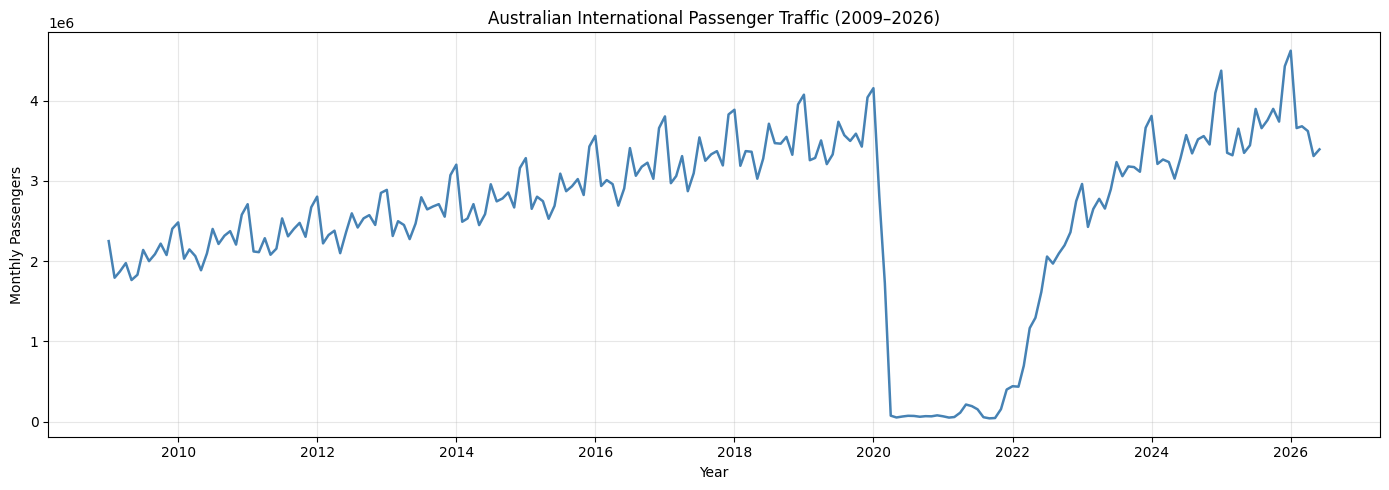

In [80]:

# Create a line chart of monthly passenger traffic
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_df["month"],
    monthly_df["total_passengers"],
    color="steelblue",
    linewidth=1.8
)

# Add chart title and axis labels
plt.title("Australian International Passenger Traffic (2009–2026)")
plt.xlabel("Year")
plt.ylabel("Monthly Passengers")

# Improve readability
plt.grid(alpha=0.3)
plt.tight_layout()

# Display the chart
plt.show()



**Observation:**
- International passenger traffic showed sustained growth from 2009 to 2019.
- Traffic declined sharply during 2020–2021, reflecting the COVID-19 disruption.
- A strong recovery began in 2022, with passenger volumes reaching new peaks in subsequent years.
- Recurring monthly fluctuations suggest seasonality, which should be investigated before forecasting.



## 10. Analyse Monthly Passenger Seasonality

Calculate and visualise average monthly passenger traffic, excluding the COVID-19 disruption period (2020–2022), to identify recurring seasonal demand patterns.


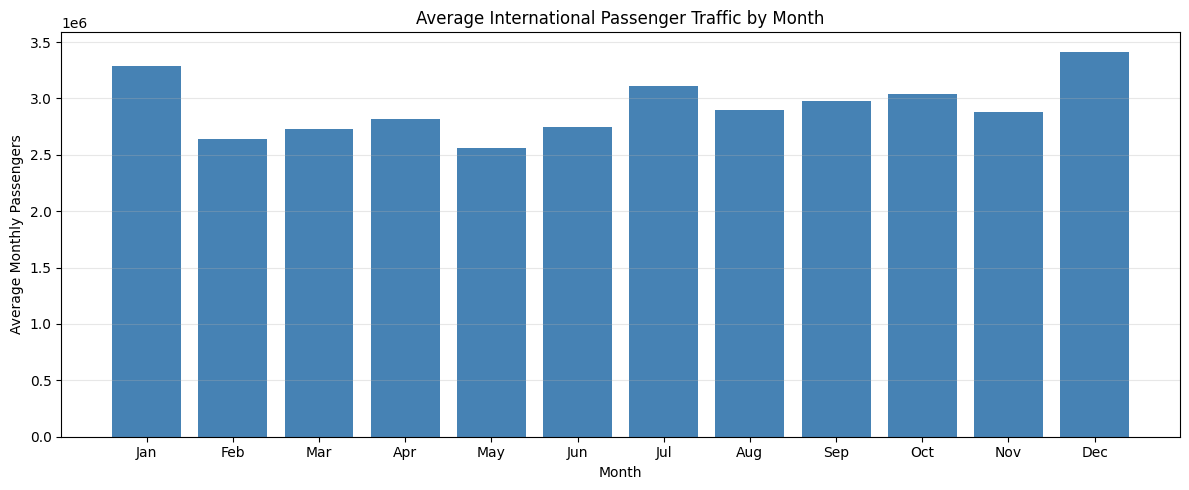

In [81]:

# Create a copy and extract year and month
seasonal_df = monthly_df.copy()
seasonal_df["year"] = seasonal_df["month"].dt.year
seasonal_df["month_num"] = seasonal_df["month"].dt.month

# Exclude COVID-19 disruption years and incomplete 2026
seasonal_df = seasonal_df[
    ~seasonal_df["year"].between(2020, 2022)
    & (seasonal_df["year"] < 2026)
]

# Calculate average passengers for each calendar month
monthly_avg = seasonal_df.groupby("month_num")["total_passengers"].mean()

# Create month labels
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Plot average monthly passenger traffic
plt.figure(figsize=(12, 5))
plt.bar(month_names, monthly_avg.values, color="steelblue")

# Add chart title and labels
plt.title("Average International Passenger Traffic by Month")
plt.xlabel("Month")
plt.ylabel("Average Monthly Passengers")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()



**Observation:**
- December and January recorded the highest average monthly passenger traffic, at approximately 3.4M and 3.3M respectively.
- May recorded the lowest average traffic, at approximately 2.6M passengers.
- The variation across calendar months suggests seasonal demand patterns, with stronger traffic around the year-end holiday period.
- These patterns support incorporating annual seasonality into forecasting models.



## 11. Analyse Year-over-Year Passenger Growth

Calculate annual international passenger totals and year-over-year growth rates to identify long-term growth, pandemic disruption, and recovery trends.


In [82]:

# Create a copy and extract the year
annual_df = monthly_df.copy()
annual_df["year"] = annual_df["month"].dt.year

# Exclude incomplete 2026 from annual comparisons
annual_df = annual_df[annual_df["year"] < 2026]

# Calculate total passengers for each year
annual_df = (
    annual_df.groupby("year")["total_passengers"]
    .sum()
    .reset_index()
)

# Calculate year-over-year passenger growth
annual_df["yoy_growth_pct"] = (
    annual_df["total_passengers"].pct_change() * 100
).round(2)

# Display annual passenger totals and growth
annual_df


,year,total_passengers,yoy_growth_pct
0,2009,24406900.0,NaN
1,2010,26790315.0,9.77
2,2011,28155009.0,5.09
3,2012,29608992.0,5.16
4,2013,31344516.0,5.86
5,2014,33133088.0,5.71
6,2015,34866649.0,5.23
7,2016,37616753.0,7.89
8,2017,39615707.0,5.31
9,2018,41575313.0,4.95



**Observation:**
- Annual international passenger traffic increased from 24.4M in 2009 to 42.5M in 2019.
- Traffic declined sharply in 2020 (-78.12%) and 2021 (-83.28%) during the COVID-19 disruption.
- Recovery began in 2022, with exceptionally high YoY growth due to the low pandemic-era base.
- By 2025, annual passenger traffic reached 44.85M, exceeding the pre-pandemic 2019 level.
- These structural changes should be considered when developing and evaluating forecasting models.



# Machine Learning Preparation

Prepare the monthly passenger time series for chronological model training, evaluation, and future demand forecasting.

## 12. Set the Time-Series Index

Convert the monthly passenger dataset into a date-indexed time series with a consistent monthly frequency.


In [83]:

# Create a separate dataset for time-series modelling
ts_df = monthly_df.copy()

# Set the month column as the time-series index
ts_df = ts_df.set_index("month")

# Ensure records are ordered chronologically
ts_df = ts_df.sort_index()

# Set a consistent monthly-start frequency
ts_df = ts_df.asfreq("MS")

# Display the first five observations
ts_df.head()


,total_passengers
month,
2009-01-01,2249424.0
2009-02-01,1793147.0
2009-03-01,1871540.0
2009-04-01,1975608.0
2009-05-01,1764508.0



## 13. Create Training and Testing Datasets

Split the monthly passenger time series chronologically into training and testing periods.

Compare two strategies:
- **Approach A:** Full historical training data, including COVID-19.
- **Approach B:** Post-COVID training data only.

Both approaches use January 2025 – June 2026 as the common testing period.


In [84]:

# Approach A: Full historical training data
train_a = ts_df.loc["2009-01":"2024-12"].copy()

# Approach B: Post-COVID training data
train_b = ts_df.loc["2023-01":"2024-12"].copy()

# Common testing period for both approaches
test = ts_df.loc["2025-01":"2026-06"].copy()

# Display the number of months in each dataset
print("Approach A - Training Months:", len(train_a))
print("Approach B - Training Months:", len(train_b))
print("Common Testing Months:", len(test))

# Verify the training and testing date ranges
print("\nApproach A:", train_a.index.min(), "to", train_a.index.max())
print("Approach B:", train_b.index.min(), "to", train_b.index.max())
print("Testing:", test.index.min(), "to", test.index.max())


Approach A - Training Months: 192
Approach B - Training Months: 24
Common Testing Months: 18

Approach A: 2009-01-01 00:00:00 to 2024-12-01 00:00:00
Approach B: 2023-01-01 00:00:00 to 2024-12-01 00:00:00
Testing: 2025-01-01 00:00:00 to 2026-06-01 00:00:00



## 14. SARIMA Forecasting Model

Train a seasonal time-series model to forecast Australia's monthly international passenger traffic using historical demand patterns.

### 14.1 Train Initial SARIMA Model

Train an initial SARIMA configuration using the full-history dataset (January 2009 – December 2024).

The model settings are exploratory and will be compared with a simpler post-COVID configuration. Systematic hyperparameter tuning was not performed.


In [85]:

# Import the SARIMA model
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Define an initial SARIMA configuration
sarima_model = SARIMAX(
    train_a["total_passengers"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Train the model using historical passenger data
sarima_fit = sarima_model.fit(disp=False)

# Display the model's information criterion
print("SARIMA model trained successfully!")
print("AIC:", round(sarima_fit.aic, 2))


SARIMA model trained successfully!
AIC: 4564.98



### 14.2 Generate SARIMA Test Predictions

Generate 18 monthly passenger forecasts for January 2025 – June 2026 using the trained SARIMA model. Compare forecasts against actual passenger traffic to assess predictive performance.


In [86]:

# Predict the next 18 months after December 2024
sarima_predictions = sarima_fit.forecast(steps=len(test))

# Create a table comparing actual and predicted passengers
sarima_results = pd.DataFrame({
    "Actual": test["total_passengers"],
    "Predicted": sarima_predictions
})

# Round predictions to whole passengers
sarima_results["Predicted"] = sarima_results["Predicted"].round(0)

# Display the comparison
display(sarima_results)


,Actual,Predicted
2025-01-01,4371977.0,4291422.0
2025-02-01,3348976.0,3808369.0
2025-03-01,3318356.0,3886796.0
2025-04-01,3649866.0,3902873.0
2025-05-01,3348058.0,3781964.0
2025-06-01,3442297.0,4007552.0
2025-07-01,3895511.0,4298696.0
2025-08-01,3655818.0,4118644.0
2025-09-01,3755774.0,4244360.0
2025-10-01,3896455.0,4280192.0



### 14.3 Evaluate SARIMA Forecast Accuracy

Evaluate the SARIMA model against actual passenger traffic from January 2025 to June 2026 using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).


In [87]:

# Import accuracy evaluation functions
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate average prediction error
sarima_mae = mean_absolute_error(
    sarima_results["Actual"],
    sarima_results["Predicted"]
)

# Calculate error metric that penalises larger mistakes
sarima_rmse = np.sqrt(mean_squared_error(
    sarima_results["Actual"],
    sarima_results["Predicted"]
))

# Display results
print(f"SARIMA MAE: {sarima_mae:,.0f} passengers")
print(f"SARIMA RMSE: {sarima_rmse:,.0f} passengers")


SARIMA MAE: 562,681 passengers
SARIMA RMSE: 634,857 passengers



**Observation:**
- The initial SARIMA model achieved an MAE of 562,681 and an RMSE of 634,857 passengers.
- Forecasts generally overestimated actual passenger traffic during the test period.
- The higher RMSE indicates that some forecasting errors were relatively large.
- A post-COVID training approach will be investigated to determine whether recent passenger patterns improve forecast accuracy.



### 14.4 Train SARIMA Using Post-COVID Data

Train a simpler SARIMA model using passenger traffic from January 2023 to December 2024 to investigate whether recent demand patterns improve forecasting performance.

The shorter training period limits how reliably annual seasonality can be estimated.


In [88]:

# Build a simpler SARIMA model using post-COVID data
sarima_model_b = SARIMAX(
    train_b["total_passengers"],
    order=(1, 1, 0),
    seasonal_order=(0, 1, 0, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Train the model
sarima_fit_b = sarima_model_b.fit(disp=False)

# Display training result
print("Post-COVID SARIMA trained successfully!")
print("AIC:", round(sarima_fit_b.aic, 2))


Post-COVID SARIMA trained successfully!
AIC: 256.87



### 14.5 Evaluate Post-COVID SARIMA Forecasts

Generate forecasts for January 2025 – June 2026 using the post-COVID SARIMA model and evaluate performance using MAE and RMSE.

Both SARIMA approaches are evaluated against the same test period for a fair comparison.


In [89]:

# Predict 18 months using the post-COVID model
sarima_predictions_b = sarima_fit_b.forecast(steps=len(test))

# Compare predictions with actual passenger traffic
sarima_results_b = pd.DataFrame({
    "Actual": test["total_passengers"],
    "Predicted": sarima_predictions_b
})

# Calculate forecasting accuracy
sarima_mae_b = mean_absolute_error(
    sarima_results_b["Actual"],
    sarima_results_b["Predicted"]
)

sarima_rmse_b = np.sqrt(mean_squared_error(
    sarima_results_b["Actual"],
    sarima_results_b["Predicted"]
))

# Display accuracy results
print(f"Post-COVID SARIMA MAE: {sarima_mae_b:,.0f} passengers")
print(f"Post-COVID SARIMA RMSE: {sarima_rmse_b:,.0f} passengers")


Post-COVID SARIMA MAE: 403,685 passengers
Post-COVID SARIMA RMSE: 476,516 passengers



### 14.6 SARIMA Model Comparison

**Observations:**
- Full-history SARIMA achieved an MAE of 562,681 and RMSE of 634,857 passengers.
- Post-COVID SARIMA achieved an MAE of 403,685 and RMSE of 476,516 passengers.
- The post-COVID approach reduced MAE by approximately 28.3% and RMSE by 24.9%.
- Recent passenger patterns may be more representative of current aviation demand than the full historical period containing COVID disruptions.
- Post-COVID SARIMA performed better on the test period, although its limited training history introduces uncertainty.

**Conclusion:** Post-COVID SARIMA is the stronger of the two tested approaches and will serve as our current SARIMA benchmark for comparison with XGBoost.



## 15. XGBoost Forecasting Model

XGBoost is a machine learning algorithm that uses decision trees to learn relationships between historical passenger traffic and predictive features.

**Objective:** Forecast Australia's monthly international passenger traffic and compare XGBoost performance with SARIMA.

**Modelling Strategy:**
- **Approach A — Full History:** Train using January 2010 – December 2024.
- **Approach B — Post-COVID:** Train using January 2023 – December 2024.

**Input Features:**
- Calendar month (`month_number`)
- Previous month's passenger traffic (`lag_1`)
- Passenger traffic from 12 months earlier (`lag_12`)

**Evaluation:** Compare both approaches against actual passenger traffic from January 2025 to June 2026 using MAE and RMSE.



### 15.1 Import XGBoost Library

Import the XGBoost regression algorithm for predicting passenger totals.


In [90]:

# Import the XGBoost regression model
from xgboost import XGBRegressor

# Check that XGBoost is available
import xgboost

print("XGBoost imported successfully!")
print("Version:", xgboost.__version__)


XGBoost imported successfully!
Version: 3.4.1



### 15.2 Create Time-Series Features

Create calendar and historical passenger features to help XGBoost learn monthly travel patterns and annual seasonality.

- **month_number:** Calendar month (1–12).
- **lag_1:** Passenger traffic from the previous month.
- **lag_12:** Passenger traffic from the same month in the previous year.


In [91]:

# Copy the monthly passenger dataset
xgb_df = ts_df.copy()

# Extract calendar month
xgb_df["month_number"] = xgb_df.index.month

# Add passenger traffic from 1 month earlier
xgb_df["lag_1"] = xgb_df["total_passengers"].shift(1)

# Add passenger traffic from 12 months earlier
xgb_df["lag_12"] = xgb_df["total_passengers"].shift(12)

# Display the first 15 rows
display(xgb_df.head(15))


,total_passengers,month_number,lag_1,lag_12
month,,,,
2009-01-01,2249424.0,1,NaN,NaN
2009-02-01,1793147.0,2,2249424.0,NaN
2009-03-01,1871540.0,3,1793147.0,NaN
2009-04-01,1975608.0,4,1871540.0,NaN
2009-05-01,1764508.0,5,1975608.0,NaN
2009-06-01,1829895.0,6,1764508.0,NaN
2009-07-01,2139351.0,7,1829895.0,NaN
2009-08-01,1999799.0,8,2139351.0,NaN
2009-09-01,2086767.0,9,1999799.0,NaN



### 15.3 Prepare XGBoost Training Data

Separate historical passenger features (X) from the target variable (y).

**Training Period:** January 2010 – December 2024 (180 observations).

**Test Period:** January 2025 – June 2026 (18 months).

The first 12 months of historical data are excluded from training because the `lag_12` feature requires passenger observations from the previous year.


In [92]:

# Select information used to predict passenger traffic
feature_cols = ["month_number", "lag_1", "lag_12"]

# Select training months only (exclude test period)
xgb_train = xgb_df.loc["2009-01":"2024-12"].dropna().copy()

# X = Input features
X_train = xgb_train[feature_cols]

# y = Actual passenger numbers to predict
y_train = xgb_train["total_passengers"]

# Display training dataset information
print("Training rows:", len(X_train))
print("Features:", feature_cols)
print("Training period:", X_train.index.min(), "to", X_train.index.max())

display(X_train.head())


Training rows: 180
Features: ['month_number', 'lag_1', 'lag_12']
Training period: 2010-01-01 00:00:00 to 2024-12-01 00:00:00


,month_number,lag_1,lag_12
month,,,
2010-01-01,1,2403191.0,2249424.0
2010-02-01,2,2482669.0,1793147.0
2010-03-01,3,2030127.0,1871540.0
2010-04-01,4,2145529.0,1975608.0
2010-05-01,5,2062773.0,1764508.0



### 15.4 Train XGBoost — Approach A (Full History)

Train an XGBoost regression model using historical passenger traffic from January 2010 to December 2024.

**Objective:** Evaluate how effectively XGBoost learns passenger demand patterns from the longer historical dataset, including COVID-related disruptions.

**Model Configuration:**
- Number of trees: 100
- Maximum tree depth: 3
- Learning rate: 0.05
- Input features: `month_number`, `lag_1`, `lag_12`


In [93]:

# Create the XGBoost regression model
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

# Train the model using historical features and passenger totals
xgb_model.fit(X_train, y_train)

# Confirm training
print("XGBoost model trained successfully!")
print("Training rows:", len(X_train))
print("Number of features:", X_train.shape[1])


XGBoost model trained successfully!
Training rows: 180
Number of features: 3



### 15.5 Generate XGBoost Test Forecasts

Generate 18 monthly passenger forecasts for January 2025 – June 2026 using recursive forecasting.

Each prediction uses historical passenger values or earlier model predictions, preventing future actual passenger data from leaking into the forecasts.


In [94]:

# Store passenger history available before the test period
passenger_history = ts_df.loc[
    :"2024-12", "total_passengers"
].to_dict()

# Store future predictions
xgb_forecasts = []

# Predict each month without using actual test values
for month in test.index:

    # Get historical or previously predicted passenger values
    lag_1 = passenger_history[month - pd.DateOffset(months=1)]
    lag_12 = passenger_history[month - pd.DateOffset(months=12)]

    # Prepare input features for this month
    features = pd.DataFrame([{
        "month_number": month.month,
        "lag_1": lag_1,
        "lag_12": lag_12
    }])

    # Predict passenger traffic
    prediction = float(xgb_model.predict(features)[0])

    # Save prediction for future months
    passenger_history[month] = prediction
    xgb_forecasts.append(prediction)

# Compare predictions with actual passenger traffic
xgb_results = pd.DataFrame({
    "Actual": test["total_passengers"],
    "Predicted": xgb_forecasts
}, index=test.index)

# Display the results
display(xgb_results.round(0))


,Actual,Predicted
month,,
2025-01-01,4371977.0,3935696.0
2025-02-01,3348976.0,3256689.0
2025-03-01,3318356.0,3258442.0
2025-04-01,3649866.0,3303424.0
2025-05-01,3348058.0,3253495.0
2025-06-01,3442297.0,3366471.0
2025-07-01,3895511.0,3768103.0
2025-08-01,3655818.0,3451434.0
2025-09-01,3755774.0,3607935.0



### 15.6 Evaluate XGBoost Forecast Accuracy

Evaluate XGBoost predictions for January 2025 – June 2026 using MAE and RMSE, enabling comparison with the SARIMA forecasting models.


In [95]:

# Calculate average forecasting error
xgb_mae = mean_absolute_error(
    xgb_results["Actual"],
    xgb_results["Predicted"]
)

# Calculate RMSE, which penalises larger errors
xgb_rmse = np.sqrt(mean_squared_error(
    xgb_results["Actual"],
    xgb_results["Predicted"]
))

# Display accuracy scores
print(f"XGBoost MAE: {xgb_mae:,.0f} passengers")
print(f"XGBoost RMSE: {xgb_rmse:,.0f} passengers")


XGBoost MAE: 241,890 passengers
XGBoost RMSE: 300,352 passengers



### 15.7 Post-COVID XGBoost Modelling Strategy

A second XGBoost model is developed using January 2023 – December 2024 to examine whether recent passenger patterns improve forecasting accuracy.

The same input features and model settings are retained, allowing the effect of the training period to be explored.


In [96]:

# Select post-COVID training data
xgb_train_b = xgb_df.loc["2023-01":"2024-12"].dropna().copy()

# Separate input features and target
X_train_b = xgb_train_b[feature_cols]
y_train_b = xgb_train_b["total_passengers"]

# Create the post-COVID XGBoost model
xgb_model_b = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

# Train the model
xgb_model_b.fit(X_train_b, y_train_b)

# Display training information
print("Post-COVID XGBoost trained successfully!")
print("Training rows:", len(X_train_b))
print("Number of features:", X_train_b.shape[1])
print("Training period:", X_train_b.index.min(), "to", X_train_b.index.max())


Post-COVID XGBoost trained successfully!
Training rows: 24
Number of features: 3
Training period: 2023-01-01 00:00:00 to 2024-12-01 00:00:00



### 15.8 Generate Post-COVID XGBoost Forecasts

Generate 18 monthly passenger forecasts for January 2025 – June 2026 using the post-COVID XGBoost model.

Recursive forecasting ensures that predictions use only historical information available before the test period and earlier model forecasts.


In [97]:

# Store known passenger history up to December 2024
passenger_history_b = ts_df.loc[
    :"2024-12", "total_passengers"
].to_dict()

# Store the model's predictions
xgb_forecasts_b = []

# Forecast one month at a time
for month in test.index:

    # Get previous month's passenger traffic
    lag_1 = passenger_history_b[month - pd.DateOffset(months=1)]

    # Get passenger traffic from the same month last year
    lag_12 = passenger_history_b[month - pd.DateOffset(months=12)]

    # Prepare the three input features
    features = pd.DataFrame([{
        "month_number": month.month,
        "lag_1": lag_1,
        "lag_12": lag_12
    }])

    # Predict using post-COVID XGBoost
    prediction = float(xgb_model_b.predict(features)[0])

    # Save prediction for use in later months
    passenger_history_b[month] = prediction
    xgb_forecasts_b.append(prediction)

# Compare forecasts with actual passenger traffic
xgb_results_b = pd.DataFrame({
    "Actual": test["total_passengers"],
    "Predicted": xgb_forecasts_b
}, index=test.index)

# Display forecast comparison
display(xgb_results_b.round(0))


,Actual,Predicted
month,,
2025-01-01,4371977.0,3743376.0
2025-02-01,3348976.0,3550649.0
2025-03-01,3318356.0,3567121.0
2025-04-01,3649866.0,3541621.0
2025-05-01,3348058.0,3486944.0
2025-06-01,3442297.0,3558093.0
2025-07-01,3895511.0,3558093.0
2025-08-01,3655818.0,3511916.0
2025-09-01,3755774.0,3511916.0



### 15.9 Evaluate Post-COVID XGBoost Accuracy

Evaluate post-COVID XGBoost forecasts against actual monthly passenger traffic from January 2025 to June 2026.

Calculate MAE and RMSE to compare forecasting performance with the full-history XGBoost and SARIMA models.


In [98]:

# Calculate average absolute forecasting error
xgb_mae_b = mean_absolute_error(
    xgb_results_b["Actual"],
    xgb_results_b["Predicted"]
)

# Calculate RMSE to measure larger forecasting errors
xgb_rmse_b = np.sqrt(mean_squared_error(
    xgb_results_b["Actual"],
    xgb_results_b["Predicted"]
))

# Display accuracy results
print(f"Post-COVID XGBoost MAE: {xgb_mae_b:,.0f} passengers")
print(f"Post-COVID XGBoost RMSE: {xgb_rmse_b:,.0f} passengers")


Post-COVID XGBoost MAE: 258,176 passengers
Post-COVID XGBoost RMSE: 328,226 passengers



### 15.10 Final Forecasting Model Comparison

| Model | MAE | RMSE |
|---|---:|---:|
| SARIMA — Full History | 562,681 | 634,857 |
| SARIMA — Post-COVID | 403,685 | 476,516 |
| XGBoost — Full History | 241,890 | 300,352 |
| XGBoost — Post-COVID | 258,176 | 328,226 |

**Key Findings:**
- Full-history XGBoost achieved the lowest forecasting errors, with an MAE of 241,890 and RMSE of 300,352 passengers.
- Both XGBoost configurations outperformed the tested SARIMA configurations.
- Post-COVID training improved SARIMA performance, whereas full-history training performed slightly better for XGBoost.
- All four approaches were evaluated using recursive or multi-step forecasts over the same 18-month period (January 2025 – June 2026).

**Conclusion:**

Full-history XGBoost is the strongest-performing model in this experiment and is the leading candidate for future passenger forecasting.

**Limitation:** The test period has been used to compare multiple approaches. Results should be treated as exploratory model-selection evidence rather than an untouched final performance estimate.



## 16. Future Passenger Traffic Forecasting

### 16.1 Retrain the Selected XGBoost Model

Retrain the best-performing XGBoost configuration using all available historical passenger data through June 2026.

**Selected Model:** Full-History XGBoost

**Selection Basis:**
- MAE: 241,890 passengers
- RMSE: 300,352 passengers
- Lowest forecasting errors among the four tested configurations

**Forecast Horizon:** July 2026 – June 2027 (12 months).

The selected configuration is retained without further hyperparameter tuning. Forecasts remain subject to uncertainty, particularly over longer horizons.


In [99]:

# Prepare all available historical data through June 2026
final_train = xgb_df.loc[:"2026-06"].dropna().copy()

# Separate features and target
X_final = final_train[feature_cols]
y_final = final_train["total_passengers"]

# Create the final XGBoost model
final_xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

# Retrain using all available observations
final_xgb_model.fit(X_final, y_final)

# Confirm training
print("Final XGBoost model trained successfully!")
print("Training rows:", len(X_final))
print("Training period:", X_final.index.min(), "to", X_final.index.max())


Final XGBoost model trained successfully!
Training rows: 198
Training period: 2010-01-01 00:00:00 to 2026-06-01 00:00:00



### 16.2 Generate 12-Month Passenger Forecasts

Generate monthly international passenger traffic forecasts for July 2026 – June 2027 using the retrained XGBoost model.

**Forecasting Method:** Recursive multi-step forecasting.

Each future prediction uses historical passenger values or previously generated forecasts, ensuring no future actual observations are used.


In [100]:

# Create the 12 future monthly dates
future_months = pd.date_range(
    start="2026-07-01",
    periods=12,
    freq="MS"
)

# Store actual passenger history through June 2026
future_history = ts_df["total_passengers"].to_dict()

# Store future forecasts
future_predictions = []

# Predict passenger traffic month by month
for month in future_months:

    # Get previous month's traffic
    lag_1 = future_history[month - pd.DateOffset(months=1)]

    # Get traffic from the same month last year
    lag_12 = future_history[month - pd.DateOffset(months=12)]

    # Prepare XGBoost input features
    features = pd.DataFrame([{
        "month_number": month.month,
        "lag_1": lag_1,
        "lag_12": lag_12
    }])

    # Predict passengers using the final model
    prediction = float(final_xgb_model.predict(features)[0])

    # Save prediction for subsequent months
    future_history[month] = prediction
    future_predictions.append(prediction)

# Create the final forecast table
future_forecast_df = pd.DataFrame({
    "month": future_months,
    "forecast_passengers": np.round(future_predictions).astype(int)
})

# Display forecasts
display(future_forecast_df)


,month,forecast_passengers
0,2026-07-01,3967941
1,2026-08-01,3827391
2,2026-09-01,3909595
3,2026-10-01,4058859
4,2026-11-01,3909595
5,2026-12-01,4302657
6,2027-01-01,4319811
7,2027-02-01,3730001
8,2027-03-01,3802186
9,2027-04-01,3787114



**Forecast Observations:**

- The XGBoost model generated 12 monthly passenger forecasts for July 2026 – June 2027.
- Forecast passenger traffic ranges from approximately 3.35 million to 4.32 million passengers per month.
- January 2027 has the highest projected traffic (4,319,811 passengers), followed by December 2026 (4,302,657).
- May 2027 has the lowest projected traffic (3,348,445 passengers).
- Forecasts indicate seasonal fluctuations, with higher demand during Australia's summer holiday period.

**Business Implications:**

- Airports and airlines can use peak-demand forecasts to support workforce and capacity planning.
- Lower-demand periods may present opportunities for targeted promotions and operational optimisation.
- Forecasts should be interpreted as estimates rather than guaranteed passenger volumes.

**Limitation:** Historical model accuracy does not guarantee future forecasting performance. Unexpected economic, regulatory, or aviation industry changes may affect actual passenger demand.



### 16.3 Visualise Historical and Forecasted Passenger Traffic

Visualise actual monthly international passenger traffic alongside XGBoost forecasts.

**Historical Period:** January 2023 – June 2026  
**Forecast Period:** July 2026 – June 2027

The chart distinguishes observed passenger traffic from future predictions and highlights expected seasonal demand patterns.


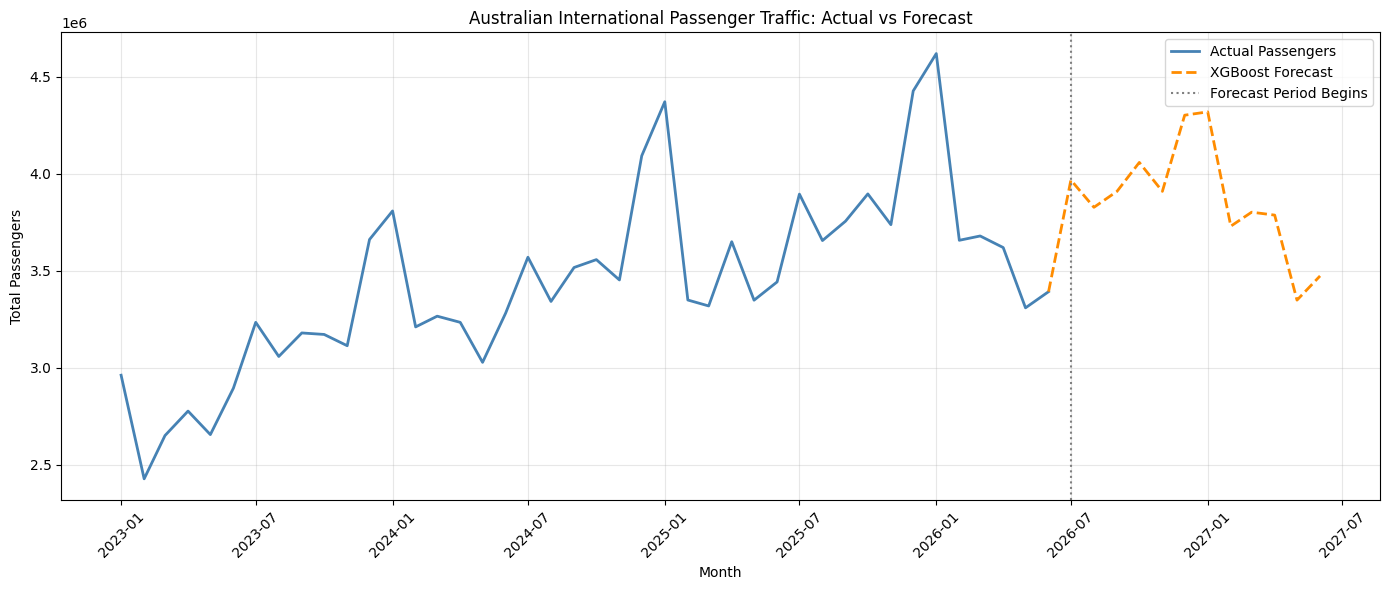

In [101]:

# Select recent historical passenger traffic
historical_data = ts_df.loc["2023-01":"2026-06"]

# Create the chart
plt.figure(figsize=(14, 6))

# Plot actual passenger traffic
plt.plot(
    historical_data.index,
    historical_data["total_passengers"],
    label="Actual Passengers",
    color="steelblue",
    linewidth=2
)

# Connect the forecast to the last actual observation
forecast_dates = pd.DatetimeIndex(
    [historical_data.index[-1]] + future_forecast_df["month"].tolist()
)

forecast_values = [
    historical_data["total_passengers"].iloc[-1]
] + future_forecast_df["forecast_passengers"].tolist()

# Plot predicted passenger traffic
plt.plot(
    forecast_dates,
    forecast_values,
    label="XGBoost Forecast",
    color="darkorange",
    linestyle="--",
    linewidth=2
)

# Mark where forecasting begins
plt.axvline(
    pd.Timestamp("2026-07-01"),
    color="gray",
    linestyle=":",
    label="Forecast Period Begins"
)

# Add chart details
plt.title("Australian International Passenger Traffic: Actual vs Forecast")
plt.xlabel("Month")
plt.ylabel("Total Passengers")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Display the chart
plt.show()



**Observations:**

- Historical international passenger traffic generally recovered between 2023 and 2025, with noticeable monthly fluctuations.
- The XGBoost forecast indicates continued seasonal variation from July 2026 to June 2027.
- January 2027 is projected to have the highest passenger traffic (4.32 million), followed by December 2026 (4.30 million).
- May 2027 is projected to have the lowest traffic (3.35 million).
- The forecast suggests higher passenger demand during Australia's summer holiday season.

**Business Implications:**

- Airlines and airports can use peak-period forecasts to support capacity and workforce planning.
- Lower-demand periods may provide opportunities for promotional strategies and operational optimisation.
- Forecasts are estimates and should be monitored against actual passenger traffic as new data becomes available.



### 16.4 Export Final Forecasting Results

Export the final XGBoost passenger traffic forecasts for July 2026 – June 2027 into a CSV file.

**Output File:** `australian_passenger_forecast_2026_2027.csv`

**Dataset Contents:**
- `month`: Forecast month.
- `forecast_passengers`: Predicted monthly international passenger traffic.

The exported dataset contains 12 monthly forecasts and can be used for reporting, visualisation, and future business analysis.


In [102]:

# Export the final 12-month XGBoost forecasts
future_forecast_df.to_csv(
    "australian_passenger_forecast_2026_2027.csv",
    index=False
)

# Confirm successful export
print("Forecast file exported successfully!")
print("File: australian_passenger_forecast_2026_2027.csv")
print("Total forecast months:", len(future_forecast_df))

# Preview exported forecasting results
display(future_forecast_df.head())


Forecast file exported successfully!
File: australian_passenger_forecast_2026_2027.csv
Total forecast months: 12


,month,forecast_passengers
0,2026-07-01,3967941
1,2026-08-01,3827391
2,2026-09-01,3909595
3,2026-10-01,4058859
4,2026-11-01,3909595


In [103]:

# Download the forecasting CSV file
from google.colab import files

files.download("australian_passenger_forecast_2026_2027.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## 17. Project Conclusion

### 17.1 Project Overview

The Australian International Aviation Intelligence project analysed historical international passenger traffic using Python, PostgreSQL, Power BI, and machine learning.

The forecasting component aimed to predict future monthly passenger demand and identify a suitable forecasting model.

### 17.2 Key Findings

- International passenger traffic experienced a major decline during COVID-19, followed by a strong recovery.
- Passenger demand demonstrated seasonal patterns, with higher traffic generally observed during December and January.
- Four forecasting approaches were evaluated: full-history and post-COVID versions of SARIMA and XGBoost.
- Full-history XGBoost achieved the lowest forecasting errors, with an MAE of 241,890 and RMSE of 300,352 passengers.
- The selected XGBoost model generated 12 monthly forecasts covering July 2026 to June 2027.
- January 2027 recorded the highest projected demand at approximately 4.32 million passengers.

### 17.3 Business Implications

The forecasting results can support:

- Airport workforce and operational capacity planning.
- Airline scheduling and resource allocation.
- Seasonal passenger demand management.
- Data-driven strategic decision-making.

### 17.4 Project Limitations

- Missing route-level passenger values may affect aggregated national totals.
- COVID-related disruptions influenced historical passenger patterns.
- Forecasting models cannot fully anticipate unexpected economic, regulatory, or operational changes.
- Model performance was compared using a shared test period, and additional independent validation would strengthen confidence in future forecasts.

### 17.5 Final Conclusion

XGBoost demonstrated the strongest forecasting performance among the four evaluated approaches.

The project successfully combined data preparation, exploratory analysis, SQL, business intelligence, and machine learning to produce meaningful aviation insights and future passenger demand forecasts.
